In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [2]:
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")



In [4]:
df.columns = df.columns.str.strip().str.lower()

df = df.drop_duplicates()

df = df.dropna(subset=["target"])

X = df.drop("target", axis=1)
y = pd.to_numeric(df["target"], errors="coerce")

valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)

X = X.apply(pd.to_numeric, errors="coerce")

X = X.dropna(axis=1, how="all")

X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

print("Dataset shape:", X.shape)
print("\nClass distribution:")
print(y.value_counts().sort_index())

print("\nClass proportions:")
print(y.value_counts(normalize=True).sort_index().round(3))

Dataset shape: (302, 13)

Class distribution:
target
0    138
1    164
Name: count, dtype: int64

Class proportions:
target
0    0.457
1    0.543
Name: proportion, dtype: float64


In [5]:
def custom_kfold(n_samples, n_splits=5, random_state=42):

    if n_splits < 2:
        raise ValueError("Number of folds must be at least 2.")

    if n_splits > n_samples:
        raise ValueError("Number of folds cannot exceed sample count.")

    rng = np.random.RandomState(random_state)

    indices = np.arange(n_samples)
    rng.shuffle(indices)

    folds = np.array_split(indices, n_splits)

    split_results = []

    for fold_number in range(n_splits):

        validation_indices = folds[fold_number]

        training_indices = np.concatenate([
            folds[i]
            for i in range(n_splits)
            if i != fold_number
        ])

        split_results.append(
            (training_indices, validation_indices)
        )

    return split_results


print("Custom K-Fold function created.")

Custom K-Fold function created.


In [6]:
def custom_stratified_kfold(y, n_splits=5, random_state=42):

    y_array = np.asarray(y)

    if n_splits < 2:
        raise ValueError("Number of folds must be at least 2.")

    class_counts = pd.Series(y_array).value_counts()

    if class_counts.min() < n_splits:
        raise ValueError(
            "Number of folds cannot exceed the smallest class count."
        )

    rng = np.random.RandomState(random_state)

    class_folds = [[] for _ in range(n_splits)]

    for class_value in np.unique(y_array):

        class_indices = np.where(y_array == class_value)[0]

        rng.shuffle(class_indices)

        divided_indices = np.array_split(
            class_indices,
            n_splits
        )

        for fold_number in range(n_splits):
            class_folds[fold_number].extend(
                divided_indices[fold_number]
            )

    
    all_indices = np.arange(len(y_array))

    split_results = []

    for fold_number in range(n_splits):

        validation_indices = np.array(
            class_folds[fold_number],
            dtype=int
        )

        rng.shuffle(validation_indices)

        training_indices = np.setdiff1d(
            all_indices,
            validation_indices
        )

        split_results.append(
            (training_indices, validation_indices)
        )

    return split_results


print("Custom Stratified K-Fold function created.")

Custom Stratified K-Fold function created.


In [7]:
fold_counts = [3, 5, 10]
minimum_class_count = y.value_counts().min()

valid_fold_counts = [
    k for k in fold_counts
    if k <= minimum_class_count and k <= len(y)
]

print("Requested fold counts:", fold_counts)
print("Valid fold counts:", valid_fold_counts)

if not valid_fold_counts:
    raise ValueError(
        "Not enough samples in the smallest class for cross-validation."
    )

Requested fold counts: [3, 5, 10]
Valid fold counts: [3, 5, 10]


In [8]:
balance_results = []

for k in valid_fold_counts:

    split_methods = {
        "Custom K-Fold": custom_kfold(
            len(X), k, random_state=42
        ),
        "Custom Stratified K-Fold": custom_stratified_kfold(
            y, k, random_state=42
        )
    }

    for method_name, splits in split_methods.items():

        for fold_number, (train_idx, val_idx) in enumerate(
            splits, start=1
        ):

            validation_y = y.iloc[val_idx]

            counts = validation_y.value_counts()

            row = {
                "Method": method_name,
                "Folds": k,
                "Fold": fold_number,
                "Validation Samples": len(val_idx)
            }

            for class_value in sorted(y.unique()):
                row[f"Class {class_value} Count"] = int(
                    counts.get(class_value, 0)
                )

            balance_results.append(row)

balance_df = pd.DataFrame(balance_results)

print(balance_df.to_string(index=False))

                  Method  Folds  Fold  Validation Samples  Class 0 Count  Class 1 Count
           Custom K-Fold      3     1                 101             52             49
           Custom K-Fold      3     2                 101             42             59
           Custom K-Fold      3     3                 100             44             56
Custom Stratified K-Fold      3     1                 101             46             55
Custom Stratified K-Fold      3     2                 101             46             55
Custom Stratified K-Fold      3     3                 100             46             54
           Custom K-Fold      5     1                  61             32             29
           Custom K-Fold      5     2                  61             29             32
           Custom K-Fold      5     3                  60             23             37
           Custom K-Fold      5     4                  60             27             33
           Custom K-Fold      5 

In [9]:
def train_and_evaluate_fold(X_train, X_validation, y_train, y_validation):

    imputer = SimpleImputer(strategy="median")

    X_train_ready = imputer.fit_transform(X_train)
    X_validation_ready = imputer.transform(X_validation)

    model = RandomForestClassifier(
        n_estimators=150,
        max_depth=8,
        random_state=42,
        class_weight="balanced"
    )

    model.fit(X_train_ready, y_train)

    predictions = model.predict(X_validation_ready)

    accuracy = accuracy_score(y_validation, predictions)

    precision = precision_score(
        y_validation,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_validation,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_validation,
        predictions,
        zero_division=0
    )

    return accuracy, precision, recall, f1


print("Training and evaluation function created.")

Training and evaluation function created.


In [10]:
cv_results = []

random_seeds = [42, 21, 7]

for k in valid_fold_counts:

    for seed in random_seeds:

        split_methods = {
            "Custom K-Fold": custom_kfold(
                len(X),
                k,
                random_state=seed
            ),

            "Custom Stratified K-Fold": custom_stratified_kfold(
                y,
                k,
                random_state=seed
            )
        }

        for method_name, splits in split_methods.items():

            for fold_number, (train_idx, val_idx) in enumerate(
                splits, start=1
            ):

                X_train_fold = X.iloc[train_idx]
                X_validation_fold = X.iloc[val_idx]

                y_train_fold = y.iloc[train_idx]
                y_validation_fold = y.iloc[val_idx]

                accuracy, precision, recall, f1 = (
                    train_and_evaluate_fold(
                        X_train_fold,
                        X_validation_fold,
                        y_train_fold,
                        y_validation_fold
                    )
                )

                cv_results.append({
                    "Method": method_name,
                    "Folds": k,
                    "Repeat": seed,
                    "Fold": fold_number,
                    "Training Samples": len(train_idx),
                    "Validation Samples": len(val_idx),
                    "Accuracy": accuracy,
                    "Precision": precision,
                    "Recall": recall,
                    "F1 Score": f1
                })

cv_results_df = pd.DataFrame(cv_results)

print("Cross-validation completed.")
print("Total fold evaluations:", len(cv_results_df))

print(cv_results_df.head(10).round(4))

Cross-validation completed.
Total fold evaluations: 108
                     Method  Folds  Repeat  Fold  Training Samples  \
0             Custom K-Fold      3      42     1               201   
1             Custom K-Fold      3      42     2               201   
2             Custom K-Fold      3      42     3               202   
3  Custom Stratified K-Fold      3      42     1               201   
4  Custom Stratified K-Fold      3      42     2               201   
5  Custom Stratified K-Fold      3      42     3               202   
6             Custom K-Fold      3      21     1               201   
7             Custom K-Fold      3      21     2               201   
8             Custom K-Fold      3      21     3               202   
9  Custom Stratified K-Fold      3      21     1               201   

   Validation Samples  Accuracy  Precision  Recall  F1 Score  
0                 101    0.8020     0.7544  0.8776    0.8113  
1                 101    0.8119     0.8333  0.8

In [11]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

cv_summary = (
    cv_results_df
    .groupby(["Method", "Folds"])[metrics]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

print("CROSS-VALIDATION PERFORMANCE SUMMARY")
print("------------------------------------")

print(cv_summary)

CROSS-VALIDATION PERFORMANCE SUMMARY
------------------------------------
                               Accuracy                         Precision  \
                                   mean     std     min     max      mean   
Method                   Folds                                              
Custom K-Fold            3       0.8157  0.0166  0.7921  0.8416    0.8098   
                         5       0.8180  0.0443  0.7049  0.9000    0.8111   
                         10      0.8279  0.0702  0.6333  0.9667    0.8217   
Custom Stratified K-Fold 3       0.8190  0.0227  0.7921  0.8614    0.8094   
                         5       0.8223  0.0380  0.7627  0.8833    0.8120   
                         10      0.8314  0.0625  0.7333  0.9355    0.8303   

                                                        Recall          \
                                   std     min     max    mean     std   
Method                   Folds                                           
Custom K-F

In [12]:
variance_results = (
    cv_results_df
    .groupby(["Method", "Folds"])[metrics]
    .std()
    .reset_index()
)

print("PERFORMANCE VARIANCE")
print("--------------------")

print(variance_results.round(4))

variance_results["Average Metric Std"] = (
    variance_results[metrics].mean(axis=1)
)

print("\nOVERALL VARIANCE COMPARISON")

print(
    variance_results[
        ["Method", "Folds", "Average Metric Std"]
    ].round(4)
)

PERFORMANCE VARIANCE
--------------------
                     Method  Folds  Accuracy  Precision  Recall  F1 Score
0             Custom K-Fold      3    0.0166     0.0311  0.0323    0.0182
1             Custom K-Fold      5    0.0443     0.0579  0.0699    0.0450
2             Custom K-Fold     10    0.0702     0.0882  0.0890    0.0714
3  Custom Stratified K-Fold      3    0.0227     0.0316  0.0593    0.0227
4  Custom Stratified K-Fold      5    0.0380     0.0462  0.0623    0.0353
5  Custom Stratified K-Fold     10    0.0625     0.0651  0.0901    0.0575

OVERALL VARIANCE COMPARISON
                     Method  Folds  Average Metric Std
0             Custom K-Fold      3              0.0246
1             Custom K-Fold      5              0.0543
2             Custom K-Fold     10              0.0797
3  Custom Stratified K-Fold      3              0.0341
4  Custom Stratified K-Fold      5              0.0454
5  Custom Stratified K-Fold     10              0.0688


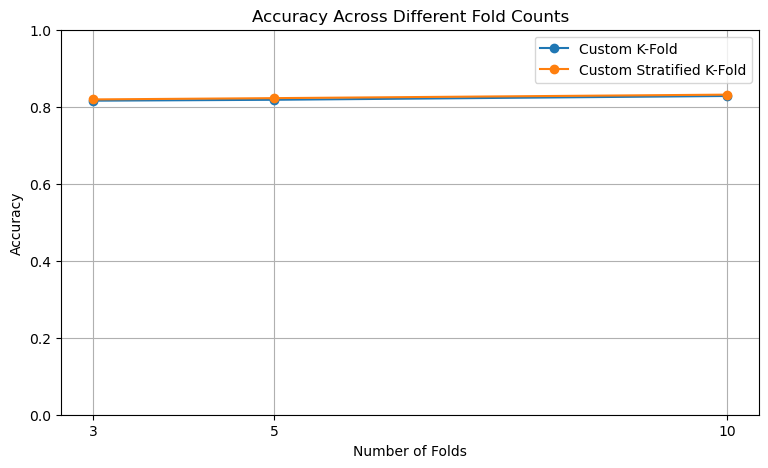

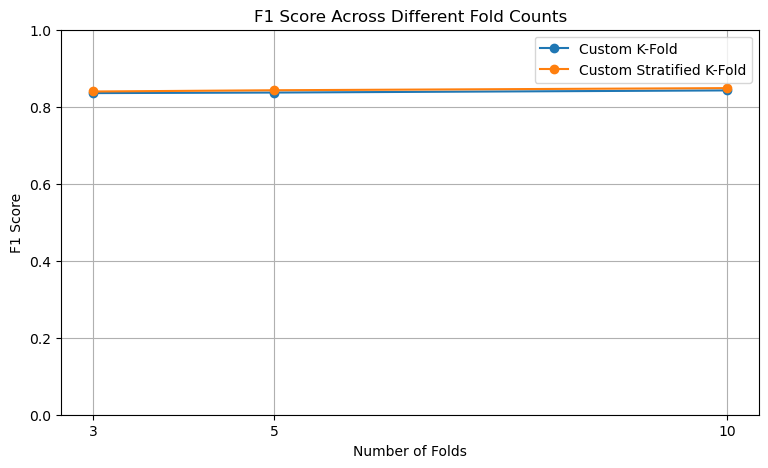

In [13]:
mean_results = (
    cv_results_df
    .groupby(["Method", "Folds"])[
        ["Accuracy", "F1 Score"]
    ]
    .mean()
    .reset_index()
)

for metric in ["Accuracy", "F1 Score"]:

    plt.figure(figsize=(9, 5))

    for method in mean_results["Method"].unique():

        subset = mean_results[
            mean_results["Method"] == method
        ]

        plt.plot(
            subset["Folds"],
            subset[metric],
            marker="o",
            label=method
        )

    plt.title(f"{metric} Across Different Fold Counts")
    plt.xlabel("Number of Folds")
    plt.ylabel(metric)
    plt.xticks(valid_fold_counts)
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True)
    plt.show()

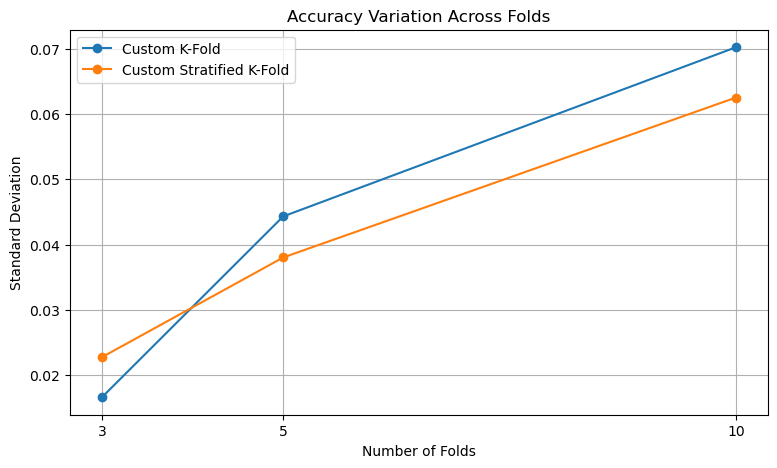

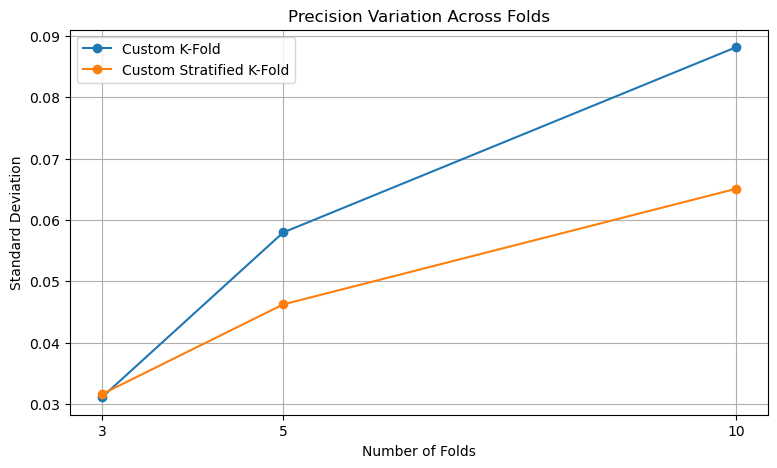

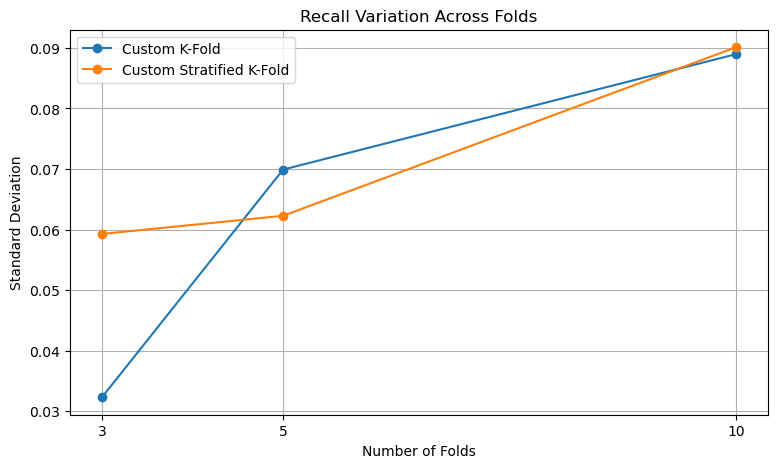

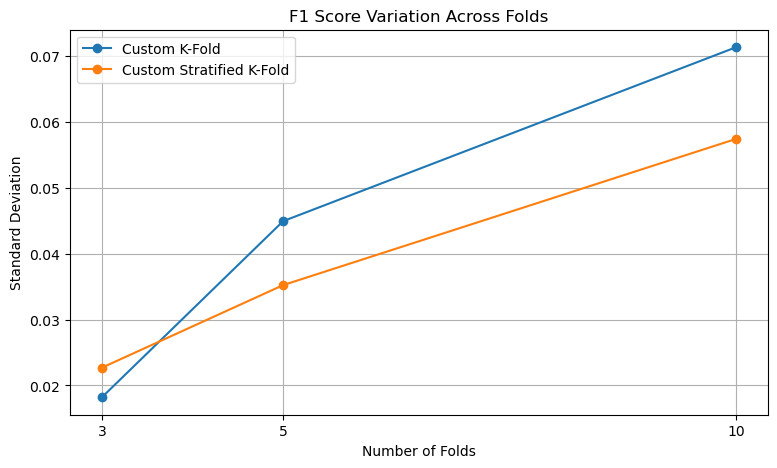

In [14]:
for metric in metrics:

    plt.figure(figsize=(9, 5))

    for method in variance_results["Method"].unique():

        subset = variance_results[
            variance_results["Method"] == method
        ]

        plt.plot(
            subset["Folds"],
            subset[metric],
            marker="o",
            label=method
        )

    plt.title(f"{metric} Variation Across Folds")
    plt.xlabel("Number of Folds")
    plt.ylabel("Standard Deviation")
    plt.xticks(valid_fold_counts)
    plt.legend()
    plt.grid(True)
    plt.show()

In [15]:
print("CLASS BALANCE COMPARISON")
print("------------------------")

for method in balance_df["Method"].unique():

    subset = balance_df[
        balance_df["Method"] == method
    ]

    print("\nMethod:", method)

    for k in valid_fold_counts:

        fold_data = subset[subset["Folds"] == k]

        print(f"\n{k}-Fold validation:")

        class_columns = [
            column for column in fold_data.columns
            if column.startswith("Class ")
        ]

        print(
            fold_data[
                ["Fold", "Validation Samples"] + class_columns
            ].to_string(index=False)
        )

CLASS BALANCE COMPARISON
------------------------

Method: Custom K-Fold

3-Fold validation:
 Fold  Validation Samples  Class 0 Count  Class 1 Count
    1                 101             52             49
    2                 101             42             59
    3                 100             44             56

5-Fold validation:
 Fold  Validation Samples  Class 0 Count  Class 1 Count
    1                  61             32             29
    2                  61             29             32
    3                  60             23             37
    4                  60             27             33
    5                  60             27             33

10-Fold validation:
 Fold  Validation Samples  Class 0 Count  Class 1 Count
    1                  31             16             15
    2                  31             17             14
    3                  30             16             14
    4                  30             12             18
    5                  30 

In [16]:
stability_summary = (
    cv_results_df
    .groupby(["Method", "Folds"])[metrics]
    .std()
    .mean(axis=1)
    .reset_index(name="Average Standard Deviation")
)

stability_summary = stability_summary.sort_values(
    "Average Standard Deviation"
).reset_index(drop=True)

print("MODEL STABILITY RANKING")
print("-----------------------")

print(stability_summary.round(4))

best_stability = stability_summary.iloc[0]

print("\nMost stable configuration:")
print("Method:", best_stability["Method"])
print("Folds:", int(best_stability["Folds"]))
print(
    "Average standard deviation:",
    round(best_stability["Average Standard Deviation"], 4)
)

MODEL STABILITY RANKING
-----------------------
                     Method  Folds  Average Standard Deviation
0             Custom K-Fold      3                      0.0246
1  Custom Stratified K-Fold      3                      0.0341
2  Custom Stratified K-Fold      5                      0.0454
3             Custom K-Fold      5                      0.0543
4  Custom Stratified K-Fold     10                      0.0688
5             Custom K-Fold     10                      0.0797

Most stable configuration:
Method: Custom K-Fold
Folds: 3
Average standard deviation: 0.0246


In [17]:
best_mean = mean_results.loc[
    mean_results["F1 Score"].idxmax()
]

report = f"""
CUSTOM CROSS-VALIDATION REPORT
==============================

Dataset:
Heart Disease Classification Dataset

Model:
Random Forest Classifier

Cross-validation methods:
1. Custom K-Fold
2. Custom Stratified K-Fold

Fold counts tested:
{valid_fold_counts}

Number of repetitions:
{len(random_seeds)}

Total evaluations:
{len(cv_results_df)}

BEST AVERAGE F1 CONFIGURATION
-----------------------------

Method: {best_mean['Method']}
Folds: {int(best_mean['Folds'])}
Mean F1 Score: {best_mean['F1 Score']:.4f}

MOST STABLE CONFIGURATION
-------------------------

Method: {best_stability['Method']}
Folds: {int(best_stability['Folds'])}
Average Standard Deviation:
{best_stability['Average Standard Deviation']:.4f}

INTERPRETATION
--------------

Mean performance indicates the average predictive performance
across validation folds and repetitions.

Standard deviation indicates how much the performance changes
when different validation samples are selected.

Stratified K-Fold aims to preserve class proportions in each
validation fold, which is useful when the target classes are
imbalanced.

A lower standard deviation suggests more consistent results,
but does not automatically mean better predictive performance.

These results measure internal cross-validation performance.
They do not establish generalization to an independent external
dataset.
"""

with open(
    "custom_cross_validation_report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print(report)


CUSTOM CROSS-VALIDATION REPORT

Dataset:
Heart Disease Classification Dataset

Model:
Random Forest Classifier

Cross-validation methods:
1. Custom K-Fold
2. Custom Stratified K-Fold

Fold counts tested:
[3, 5, 10]

Number of repetitions:
3

Total evaluations:
108

BEST AVERAGE F1 CONFIGURATION
-----------------------------

Method: Custom Stratified K-Fold
Folds: 10
Mean F1 Score: 0.8483

MOST STABLE CONFIGURATION
-------------------------

Method: Custom K-Fold
Folds: 3
Average Standard Deviation:
0.0246

INTERPRETATION
--------------

Mean performance indicates the average predictive performance
across validation folds and repetitions.

Standard deviation indicates how much the performance changes
when different validation samples are selected.

Stratified K-Fold aims to preserve class proportions in each
validation fold, which is useful when the target classes are
imbalanced.

A lower standard deviation suggests more consistent results,
but does not automatically mean better predi

In [18]:
cv_results_df.to_csv(
    "custom_cross_validation_fold_results.csv",
    index=False
)

balance_df.to_csv(
    "custom_cross_validation_class_balance.csv",
    index=False
)

variance_results.to_csv(
    "custom_cross_validation_variance.csv",
    index=False
)

stability_summary.to_csv(
    "custom_cross_validation_stability.csv",
    index=False
)

mean_results.to_csv(
    "custom_cross_validation_mean_performance.csv",
    index=False
)

print("All cross-validation files exported successfully.")

All cross-validation files exported successfully.
